# Transformer básico para series de tiempo
### Notebook 2 de 2 · Implementación del encoder Transformer desde cero en PyTorch

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/RubyDayana/transformers-series-tiempo/blob/main/notebooks/02_Transformer_Series_Tiempo.ipynb)

- **Estudiante:** Ruby Dayana Cárdenas Gómez
- **Curso:** CADI Deep Learning Conceptos - Universidad de Cundinamarca
- **Docente:** Nidia Stella García Roa
- **Repositorio:** https://github.com/RubyDayana/transformers-series-tiempo

---

**Objetivo.** Construir, pieza por pieza, el encoder de la arquitectura Transformer de
*Attention Is All You Need* (Vaswani et al., 2017) y aplicarlo a la misma tarea del notebook 1:
predecir la temperatura mínima del día siguiente a partir de los 30 días anteriores.

**Contenido**
1. Librerías y configuración
2. Datos y preprocesamiento (igual que el notebook 1)
3. Componentes del Transformer: embedding, codificación posicional, atención multi-cabeza, *feed-forward*, residuales y normalización
4. Ensamble del modelo
5. Entrenamiento y comparación con LSTM
6. Experimento de ablación: Transformer **sin** codificación posicional
7. Visualización de la atención por cabeza
8. Análisis y conclusiones

In [1]:
# ==============================================================================
# 1. Librerías, semilla y dispositivo
# ==============================================================================
import os, math, time, random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

SEED = 42
def fijar_semilla(s=SEED):
    """Fija las semillas para que los resultados se puedan repetir."""
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
fijar_semilla()

def n_parametros(m):
    """Número de parámetros entrenables de un modelo."""
    return sum(p.numel() for p in m.parameters() if p.requires_grad)

device = "cuda" if torch.cuda.is_available() else "cpu"
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .3})
print(f"PyTorch {torch.__version__} | NumPy {np.__version__} | Pandas {pd.__version__}")
print(f"Dispositivo: {device.upper()}")

PyTorch 2.15.0+cu132 | NumPy 2.5.3 | Pandas 3.0.5
Dispositivo: CPU


## 2. Datos
Mismo dataset, misma partición cronológica, misma normalización y mismas ventanas de 30 días que en el notebook 1, para que los resultados sean comparables.

In [2]:
# ==============================================================================
# 2. Carga de datos: temperatura mínima diaria en Melbourne (1981-1990)
# ==============================================================================
URL = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/daily-min-temperatures.csv"
LOCAL = "../data/daily-min-temperatures.csv"           # copia incluida en el repositorio

df = pd.read_csv(LOCAL if os.path.exists(LOCAL) else URL, parse_dates=["Date"])
# Algunas versiones del archivo traen valores como "?0.2": se limpian por seguridad
df["Temp"] = pd.to_numeric(df["Temp"].astype(str).str.replace("?", "", regex=False))
df = df.sort_values("Date").reset_index(drop=True)

print(f"Registros: {len(df)} | Desde {df.Date.min().date()} hasta {df.Date.max().date()}")
print(f"Valores nulos: {df.Temp.isna().sum()}")
display(df.head())
display(df.Temp.describe().round(2).to_frame().T)

Registros: 3650 | Desde 1981-01-01 hasta 1990-12-31
Valores nulos: 0


,Date,Temp
0,1981-01-01,20.7
1,1981-01-02,17.9
2,1981-01-03,18.8
3,1981-01-04,14.6
4,1981-01-05,15.8


,count,mean,std,min,25%,50%,75%,max
Temp,3650.0,11.18,4.07,0.0,8.3,11.0,14.0,26.3


In [3]:
# ==============================================================================
# 3. Partición cronológica, normalización y ventanas deslizantes
# ==============================================================================
LOOKBACK = 30          # días de historia que ve el modelo
serie = df.Temp.values.astype(np.float32)
fechas = df.Date.values

fin_train = int((df.Date < "1989-01-01").sum())   # 1981-1988 → entrenamiento
fin_val   = int((df.Date < "1990-01-01").sum())   # 1989      → validación
fin_test  = len(df)                               # 1990      → prueba

# La media y la desviación se calculan SOLO con entrenamiento (evita fuga de información)
MU, SD = serie[:fin_train].mean(), serie[:fin_train].std()
z = (serie - MU) / SD

def crear_ventanas(z, inicio, fin, lookback=LOOKBACK):
    """X[i] = 30 días anteriores al día t, y[i] = temperatura del día t."""
    X, y, idx = [], [], []
    for t in range(max(inicio, lookback), fin):
        X.append(z[t - lookback:t]); y.append(z[t]); idx.append(t)
    return (torch.tensor(np.array(X)), torch.tensor(np.array(y)), np.array(idx))

Xtr, ytr, itr = crear_ventanas(z, 0, fin_train)
Xva, yva, iva = crear_ventanas(z, fin_train, fin_val)
Xte, yte, ite = crear_ventanas(z, fin_val, fin_test)
print(f"Media train = {MU:.2f} °C | Desv. train = {SD:.2f} °C")
print(f"Ventanas → train {tuple(Xtr.shape)} | val {tuple(Xva.shape)} | test {tuple(Xte.shape)}")

Media train = 11.11 °C | Desv. train = 4.06 °C
Ventanas → train (2890, 30) | val (365, 30) | test (365, 30)


## 3. Componentes del Transformer

```
 x (30 días) ─► Embedding lineal (1 → d_model) ─► + Codificación posicional
                      │
           ┌──────────▼───────────┐
           │ Atención multi-cabeza│──► + residual ─► LayerNorm        ┐
           │ Feed-forward (FFN)   │──► + residual ─► LayerNorm        ┘ × N capas
           └──────────┬───────────┘
                      ▼
         Representación del último día ─► Lineal ─► temperatura del día siguiente
```

### 3.1 Embedding de entrada
En NLP cada palabra se convierte en un vector con una tabla de embeddings. En una serie de tiempo
cada "token" es un día con un solo número, así que el embedding es una **proyección lineal** de 1 a
$d_{model}$ dimensiones (multiplicada por $\sqrt{d_{model}}$, como en el paper).

### 3.2 Codificación posicional
La atención no sabe en qué orden llegan los elementos. Para darle esa información se suma a cada
embedding un vector de senos y cosenos de distinta frecuencia:

$$PE_{(pos,2i)}=\sin\left(\frac{pos}{10000^{2i/d_{model}}}\right),\qquad PE_{(pos,2i+1)}=\cos\left(\frac{pos}{10000^{2i/d_{model}}}\right)$$

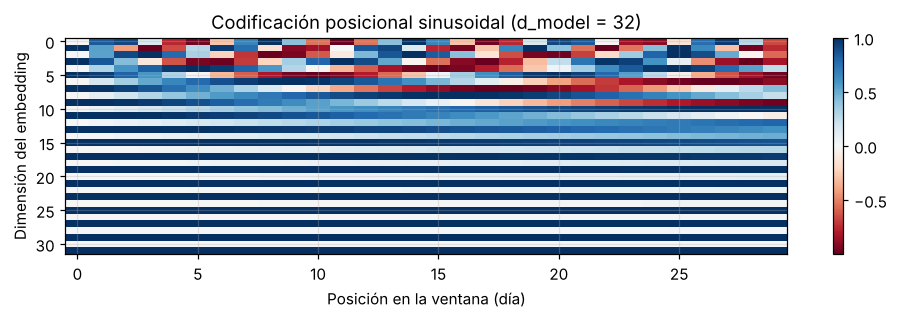

In [4]:
class CodificacionPosicional(nn.Module):
    def __init__(self, d_model, max_len=500):
        super().__init__()
        pos = torch.arange(max_len).unsqueeze(1)                                   # [max_len, 1]
        div = torch.exp(torch.arange(0, d_model, 2) * (-math.log(10000.0) / d_model))
        pe = torch.zeros(max_len, d_model)
        pe[:, 0::2] = torch.sin(pos * div)
        pe[:, 1::2] = torch.cos(pos * div)
        self.register_buffer("pe", pe)          # no es un parámetro entrenable
    def forward(self, x):                       # x: [B, T, d_model]
        return x + self.pe[: x.size(1)]

pe = CodificacionPosicional(32).pe[:LOOKBACK].numpy()
fig, ax = plt.subplots(figsize=(9, 3))
im = ax.imshow(pe.T, aspect="auto", cmap="RdBu"); plt.colorbar(im)
ax.set_xlabel("Posición en la ventana (día)"); ax.set_ylabel("Dimensión del embedding")
ax.set_title("Codificación posicional sinusoidal (d_model = 32)")
plt.tight_layout(); os.makedirs("figuras", exist_ok=True); plt.savefig("figuras/codificacion_posicional.png", dpi=150); plt.show()

### 3.3 Atención multi-cabeza (*self-attention*)
En la auto-atención las queries, keys y values salen **de la misma secuencia**: cada día "mira" a todos los
demás días de la ventana. Con varias cabezas, el modelo divide $d_{model}$ en $h$ subespacios y aprende
$h$ patrones de atención distintos en paralelo:

$$\text{MultiHead}(Q,K,V)=\text{Concat}(\text{head}_1,\dots,\text{head}_h)W^O,\quad \text{head}_i=\text{Atención}(QW_i^Q,KW_i^K,VW_i^V)$$

In [5]:
def atencion_producto_punto(Q, K, V, mascara=None):
    d_k = Q.size(-1)
    puntajes = Q @ K.transpose(-2, -1) / math.sqrt(d_k)
    if mascara is not None:
        puntajes = puntajes.masked_fill(mascara == 0, float("-inf"))
    pesos = torch.softmax(puntajes, dim=-1)
    return pesos @ V, pesos


class AtencionMultiCabeza(nn.Module):
    def __init__(self, d_model, n_cabezas, dropout=0.0):
        super().__init__()
        assert d_model % n_cabezas == 0
        self.h, self.d_k = n_cabezas, d_model // n_cabezas
        self.Wq = nn.Linear(d_model, d_model)
        self.Wk = nn.Linear(d_model, d_model)
        self.Wv = nn.Linear(d_model, d_model)
        self.Wo = nn.Linear(d_model, d_model)
        self.drop = nn.Dropout(dropout)

    def dividir(self, x):        # [B, T, d_model] → [B, h, T, d_k]
        B, T, _ = x.shape
        return x.view(B, T, self.h, self.d_k).transpose(1, 2)

    def forward(self, x, mascara=None):
        B, T, D = x.shape
        Q, K, V = self.dividir(self.Wq(x)), self.dividir(self.Wk(x)), self.dividir(self.Wv(x))
        contexto, pesos = atencion_producto_punto(Q, K, V, mascara)      # [B, h, T, d_k]
        contexto = contexto.transpose(1, 2).reshape(B, T, D)              # concatenar cabezas
        return self.Wo(self.drop(contexto)), pesos                        # pesos: [B, h, T, T]

# --- Verificación: copiamos los pesos a nn.MultiheadAttention de PyTorch y comparamos ---
fijar_semilla()
propia = AtencionMultiCabeza(32, 4)
oficial = nn.MultiheadAttention(32, 4, batch_first=True)
with torch.no_grad():
    oficial.in_proj_weight.copy_(torch.cat([propia.Wq.weight, propia.Wk.weight, propia.Wv.weight]))
    oficial.in_proj_bias.copy_(torch.cat([propia.Wq.bias, propia.Wk.bias, propia.Wv.bias]))
    oficial.out_proj.weight.copy_(propia.Wo.weight); oficial.out_proj.bias.copy_(propia.Wo.bias)
x = torch.randn(5, LOOKBACK, 32)
s1, w1 = propia(x)
s2, w2 = oficial(x, x, x, average_attn_weights=False)
print(f"Diferencia máxima en la salida: {(s1 - s2).abs().max():.2e}")
print(f"Diferencia máxima en los pesos: {(w1 - w2).abs().max():.2e}")

Diferencia máxima en la salida: 5.96e-08
Diferencia máxima en los pesos: 2.98e-08


La implementación propia coincide con `nn.MultiheadAttention` hasta el error de redondeo, así que el
bloque está bien construido.

### 3.4 Capa del encoder: *feed-forward*, conexiones residuales y normalización
Cada capa aplica (1) atención multi-cabeza y (2) una red *feed-forward* de dos capas aplicada a cada
posición por separado. Alrededor de cada subcapa hay una **conexión residual** y una **normalización
de capa** (*Add & Norm*): $\text{LayerNorm}(x + \text{Subcapa}(x))$. Las residuales facilitan que el
gradiente fluya en redes profundas.

In [6]:
class CapaEncoder(nn.Module):
    def __init__(self, d_model, n_cabezas, d_ff, dropout=0.1):
        super().__init__()
        self.atencion = AtencionMultiCabeza(d_model, n_cabezas, dropout)
        self.ffn = nn.Sequential(nn.Linear(d_model, d_ff), nn.ReLU(), nn.Dropout(dropout),
                                 nn.Linear(d_ff, d_model))
        self.norm1, self.norm2 = nn.LayerNorm(d_model), nn.LayerNorm(d_model)
        self.drop = nn.Dropout(dropout)
    def forward(self, x):
        a, pesos = self.atencion(x)
        x = self.norm1(x + self.drop(a))            # Add & Norm 1
        x = self.norm2(x + self.drop(self.ffn(x)))  # Add & Norm 2
        return x, pesos

## 4. Ensamble del modelo

Para pronóstico de un paso basta con la **parte encoder**: el modelo lee los 30 días completos y se usa
la representación del último día (que, gracias a la atención, ya contiene información de toda la ventana)
para predecir. No se necesita máscara causal porque el valor a predecir no está dentro de la entrada.

Hiperparámetros: $d_{model}=32$, 4 cabezas ($d_k=8$), 2 capas, $d_{ff}=64$, dropout 0,1.

In [7]:
class TransformerSeries(nn.Module):
    def __init__(self, d_model=32, n_cabezas=4, n_capas=2, d_ff=64, dropout=0.1, usar_pe=True, lectura="ultimo"):
        super().__init__()
        self.d_model, self.usar_pe, self.lectura = d_model, usar_pe, lectura
        self.embedding = nn.Linear(1, d_model)
        self.pe = CodificacionPosicional(d_model)
        self.drop = nn.Dropout(dropout)
        self.capas = nn.ModuleList([CapaEncoder(d_model, n_cabezas, d_ff, dropout) for _ in range(n_capas)])
        self.salida = nn.Linear(d_model, 1)
    def forward(self, x):                                   # x: [B, T]
        h = self.embedding(x.unsqueeze(-1)) * math.sqrt(self.d_model)
        if self.usar_pe:
            h = self.pe(h)
        h = self.drop(h)
        pesos = []
        for capa in self.capas:
            h, w = capa(h); pesos.append(w)
        # lectura "ultimo": representación del último día | "promedio": media de los 30 días
        z = h[:, -1] if self.lectura == "ultimo" else h.mean(1)
        return self.salida(z).squeeze(-1), pesos


class LSTMSimple(nn.Module):
    """Modelo recurrente de referencia (igual al del notebook 1)."""
    def __init__(self, oculto=64):
        super().__init__()
        self.lstm = nn.LSTM(1, oculto, batch_first=True)
        self.salida = nn.Linear(oculto, 1)
    def forward(self, x):
        H, _ = self.lstm(x.unsqueeze(-1))
        return self.salida(H[:, -1]).squeeze(-1), None

fijar_semilla(); print(TransformerSeries())
print(f"Parámetros del Transformer: {sum(p.numel() for p in TransformerSeries().parameters()):,}")

TransformerSeries(
  (embedding): Linear(in_features=1, out_features=32, bias=True)
  (pe): CodificacionPosicional()
  (drop): Dropout(p=0.1, inplace=False)
  (capas): ModuleList(
    (0-1): 2 x CapaEncoder(
      (atencion): AtencionMultiCabeza(
        (Wq): Linear(in_features=32, out_features=32, bias=True)
        (Wk): Linear(in_features=32, out_features=32, bias=True)
        (Wv): Linear(in_features=32, out_features=32, bias=True)
        (Wo): Linear(in_features=32, out_features=32, bias=True)
        (drop): Dropout(p=0.1, inplace=False)
      )
      (ffn): Sequential(
        (0): Linear(in_features=32, out_features=64, bias=True)
        (1): ReLU()
        (2): Dropout(p=0.1, inplace=False)
        (3): Linear(in_features=64, out_features=32, bias=True)
      )
      (norm1): LayerNorm((32,), eps=1e-05, elementwise_affine=True, bias=True)
      (norm2): LayerNorm((32,), eps=1e-05, elementwise_affine=True, bias=True)
      (drop): Dropout(p=0.1, inplace=False)
    )
  )
  (

## 5. Entrenamiento y comparación
Se usa exactamente la misma rutina de entrenamiento del notebook 1 (Adam, MSE, parada temprana).

In [8]:
# ==============================================================================
# Funciones de entrenamiento y evaluación (comunes a todos los modelos)
# Cada modelo devuelve (predicción, información_extra) → extra = pesos de atención o None
# ==============================================================================
def entrenar(modelo, nombre, epocas=60, lr=1e-3, bs=64, paciencia=10):
    fijar_semilla()
    modelo.to(device)
    opt = torch.optim.Adam(modelo.parameters(), lr=lr)
    perdida = nn.MSELoss()
    hist = {"train": [], "val": []}
    mejor, mejor_estado, sin_mejora = float("inf"), None, 0
    t0 = time.time()
    for ep in range(1, epocas + 1):
        modelo.train(); perm = torch.randperm(len(Xtr)); acum = 0.0
        for i in range(0, len(Xtr), bs):
            b = perm[i:i + bs]
            xb, yb = Xtr[b].to(device), ytr[b].to(device)
            opt.zero_grad()
            pred, _ = modelo(xb)
            loss = perdida(pred, yb)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(modelo.parameters(), 1.0)
            opt.step()
            acum += loss.item() * len(b)
        hist["train"].append(acum / len(Xtr))
        modelo.eval()
        with torch.no_grad():
            pv, _ = modelo(Xva.to(device))
            lv = perdida(pv, yva.to(device)).item()
        hist["val"].append(lv)
        if lv < mejor - 1e-5:
            mejor, sin_mejora = lv, 0
            mejor_estado = {k: v.detach().clone() for k, v in modelo.state_dict().items()}
        else:
            sin_mejora += 1
        if ep == 1 or ep % 10 == 0:
            print(f"[{nombre}] época {ep:3d} | MSE train {hist['train'][-1]:.4f} | MSE val {lv:.4f}")
        if sin_mejora >= paciencia:
            print(f"[{nombre}] parada temprana en la época {ep} (mejor val = {mejor:.4f})")
            break
    modelo.load_state_dict(mejor_estado)
    seg = time.time() - t0
    print(f"[{nombre}] tiempo de entrenamiento: {seg:.1f} s")
    return hist, seg

@torch.no_grad()
def predecir(modelo, X):
    """Predicción en °C (se deshace la normalización)."""
    modelo.eval()
    pred, extra = modelo(X.to(device))
    return pred.cpu().numpy() * SD + MU, extra

def metricas(real, pred):
    err = pred - real
    return {"MAE (°C)": np.abs(err).mean(), "RMSE (°C)": np.sqrt((err ** 2).mean()),
            "R²": 1 - (err ** 2).sum() / ((real - real.mean()) ** 2).sum()}

y_real_test = yte.numpy() * SD + MU
# Línea base ingenua (persistencia): mañana = hoy
pred_persist = Xte[:, -1].numpy() * SD + MU
print("Persistencia:", {k: round(float(v), 3) for k, v in metricas(y_real_test, pred_persist).items()})

Persistencia: {'MAE (°C)': 2.025, 'RMSE (°C)': 2.582, 'R²': 0.552}


In [9]:
fijar_semilla(); transformer = TransformerSeries()
hist_tr, t_tr = entrenar(transformer, "Transformer")
print()
fijar_semilla(); lstm = LSTMSimple()
hist_lstm, t_lstm = entrenar(lstm, "LSTM")

[Transformer] época   1 | MSE train 0.4396 | MSE val 0.3037


[Transformer] época  10 | MSE train 0.3802 | MSE val 0.2898


[Transformer] época  20 | MSE train 0.3734 | MSE val 0.2734


[Transformer] parada temprana en la época 27 (mejor val = 0.2719)
[Transformer] tiempo de entrenamiento: 16.9 s



[LSTM] época   1 | MSE train 0.6495 | MSE val 0.4106


[LSTM] época  10 | MSE train 0.3688 | MSE val 0.2831


[LSTM] época  20 | MSE train 0.3635 | MSE val 0.2871


[LSTM] época  30 | MSE train 0.3610 | MSE val 0.2784


[LSTM] época  40 | MSE train 0.3592 | MSE val 0.2764


[LSTM] época  50 | MSE train 0.3602 | MSE val 0.2753


[LSTM] época  60 | MSE train 0.3532 | MSE val 0.2786
[LSTM] tiempo de entrenamiento: 12.5 s


## 6. Ablación: Transformer sin codificación posicional
Sin codificación posicional la auto-atención trata la ventana como un **conjunto** de valores sin orden.
Este experimento mide cuánto aporta saber *cuándo* ocurrió cada temperatura.

In [10]:
fijar_semilla(); transformer_sin_pe = TransformerSeries(usar_pe=False)
hist_sin, t_sin = entrenar(transformer_sin_pe, "Transformer sin PE")

[Transformer sin PE] época   1 | MSE train 0.4430 | MSE val 0.3022


[Transformer sin PE] época  10 | MSE train 0.3771 | MSE val 0.2893


[Transformer sin PE] época  20 | MSE train 0.3740 | MSE val 0.2746


[Transformer sin PE] parada temprana en la época 26 (mejor val = 0.2711)
[Transformer sin PE] tiempo de entrenamiento: 16.3 s


**Segundo experimento de ablación.** Cuando la predicción se toma del último día, ese token siempre
sabe que él es "ayer" (su propio valor), aunque no tenga posición. Para aislar el papel de la codificación
posicional se cambia la lectura por el **promedio de los 30 días**: así el único modo de distinguir
ayer de hace un mes es la codificación posicional.

In [11]:
fijar_semilla(); tr_prom = TransformerSeries(lectura="promedio")
hist_prom, t_prom = entrenar(tr_prom, "Transformer promedio + PE")
print()
fijar_semilla(); tr_prom_sin = TransformerSeries(lectura="promedio", usar_pe=False)
hist_prom_sin, t_prom_sin = entrenar(tr_prom_sin, "Transformer promedio sin PE")

[Transformer promedio + PE] época   1 | MSE train 0.5265 | MSE val 0.4438


[Transformer promedio + PE] época  10 | MSE train 0.4855 | MSE val 0.3876


[Transformer promedio + PE] época  20 | MSE train 0.4625 | MSE val 0.3538


[Transformer promedio + PE] época  30 | MSE train 0.4537 | MSE val 0.3430


[Transformer promedio + PE] época  40 | MSE train 0.4263 | MSE val 0.3034


[Transformer promedio + PE] época  50 | MSE train 0.4165 | MSE val 0.2905


... (2 outputs left out)

[Transformer promedio sin PE] época  10 | MSE train 0.4948 | MSE val 0.4072


[Transformer promedio sin PE] época  20 | MSE train 0.4918 | MSE val 0.4052


[Transformer promedio sin PE] época  30 | MSE train 0.4877 | MSE val 0.4101


[Transformer promedio sin PE] parada temprana en la época 38 (mejor val = 0.3995)
[Transformer promedio sin PE] tiempo de entrenamiento: 24.0 s


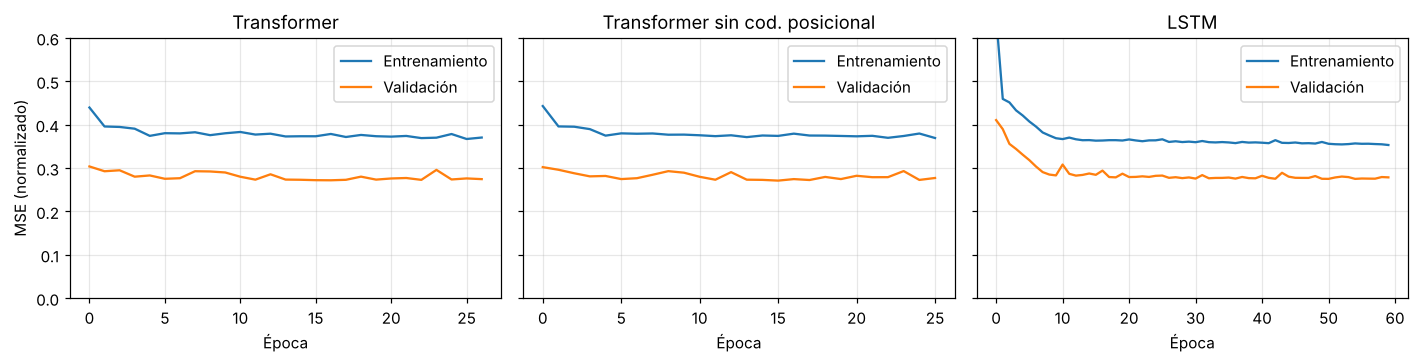

In [12]:
fig, ax = plt.subplots(1, 3, figsize=(13, 3.4), sharey=True)
for a, (h, n) in zip(ax, [(hist_tr, "Transformer"), (hist_sin, "Transformer sin cod. posicional"), (hist_lstm, "LSTM")]):
    a.plot(h["train"], label="Entrenamiento"); a.plot(h["val"], label="Validación")
    a.set_title(n); a.set_xlabel("Época"); a.legend()
ax[0].set_ylabel("MSE (normalizado)"); ax[0].set_ylim(0, 0.6)
plt.tight_layout(); plt.savefig("figuras/perdidas_transformer.png", dpi=150); plt.show()

In [13]:
p_tr, pesos_tr = predecir(transformer, Xte)
p_sin, _ = predecir(transformer_sin_pe, Xte)
p_lstm, _ = predecir(lstm, Xte)
p_prom, _ = predecir(tr_prom, Xte)
p_prom_sin, _ = predecir(tr_prom_sin, Xte)

tabla = pd.DataFrame({
    "Persistencia (mañana = hoy)": metricas(y_real_test, pred_persist),
    "LSTM": metricas(y_real_test, p_lstm),
    "Transformer (lectura último día)": metricas(y_real_test, p_tr),
    "Transformer último día, sin PE": metricas(y_real_test, p_sin),
    "Transformer (lectura promedio)": metricas(y_real_test, p_prom),
    "Transformer promedio, sin PE": metricas(y_real_test, p_prom_sin),
}).T
tabla["Parámetros"] = [0] + [n_parametros(m) for m in [lstm, transformer, transformer_sin_pe, tr_prom, tr_prom_sin]]
tabla["Épocas"] = [0] + [len(h["val"]) for h in [hist_lstm, hist_tr, hist_sin, hist_prom, hist_prom_sin]]
tabla["Tiempo (s)"] = [0, t_lstm, t_tr, t_sin, t_prom, t_prom_sin]
tabla.round(3)

,MAE (°C),RMSE (°C),R²,Parámetros,Épocas,Tiempo (s)
Persistencia (mañana = hoy),2.025,2.582,0.552,0,0,0.000
LSTM,1.722,2.244,0.661,17217,60,12.461
Transformer (lectura último día),1.753,2.269,0.654,17185,27,16.871
"Transformer último día, sin PE",1.753,2.270,0.654,17185,26,16.275
Transformer (lectura promedio),1.736,2.285,0.649,17185,60,36.668
"Transformer promedio, sin PE",1.981,2.616,0.540,17185,38,24.050


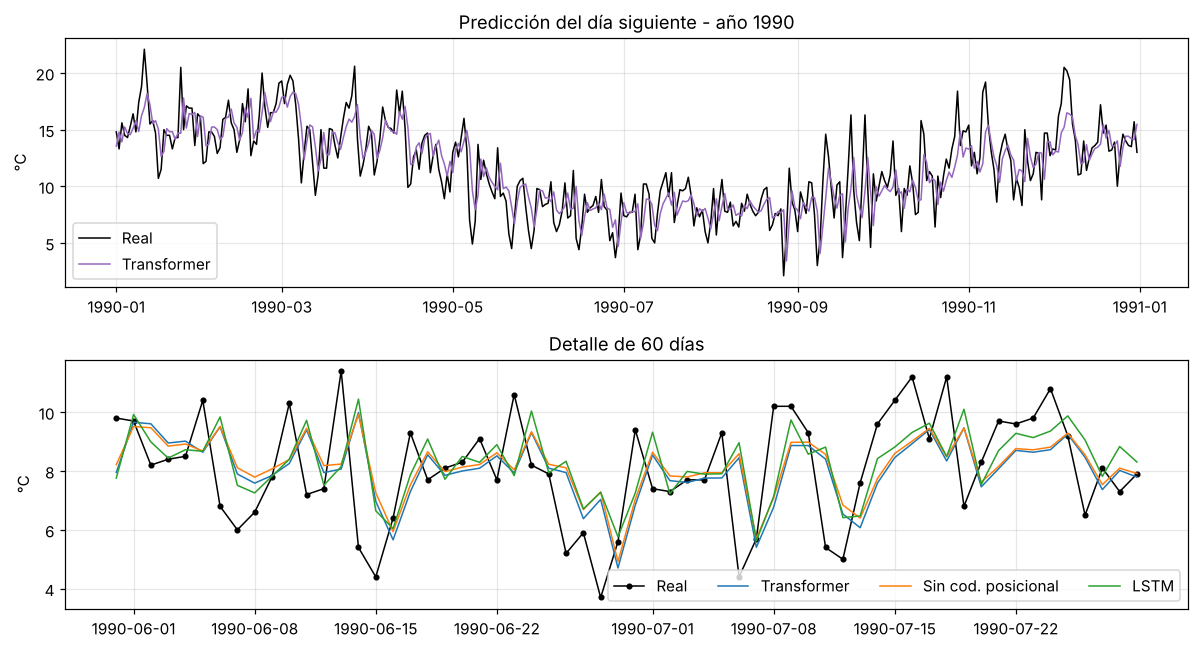

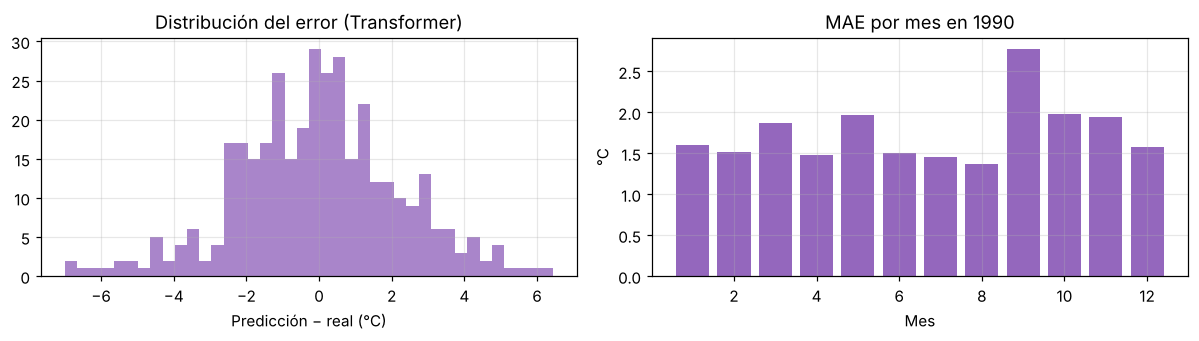

In [14]:
fechas_test = df.Date.values[ite]
fig, ax = plt.subplots(2, 1, figsize=(11, 6))
ax[0].plot(fechas_test, y_real_test, color="k", lw=1, label="Real")
ax[0].plot(fechas_test, p_tr, color="tab:purple", lw=1, label="Transformer")
ax[0].set_title("Predicción del día siguiente - año 1990"); ax[0].set_ylabel("°C"); ax[0].legend()
z = slice(150, 210)
ax[1].plot(fechas_test[z], y_real_test[z], "k.-", lw=1, label="Real")
ax[1].plot(fechas_test[z], p_tr[z], lw=1, label="Transformer")
ax[1].plot(fechas_test[z], p_sin[z], lw=1, label="Sin cod. posicional")
ax[1].plot(fechas_test[z], p_lstm[z], lw=1, label="LSTM")
ax[1].set_title("Detalle de 60 días"); ax[1].set_ylabel("°C"); ax[1].legend(ncol=4)
plt.tight_layout(); plt.savefig("figuras/predicciones_transformer.png", dpi=150); plt.show()

err = p_tr - y_real_test
fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
ax[0].hist(err, bins=40, color="tab:purple", alpha=.8); ax[0].set_title("Distribución del error (Transformer)"); ax[0].set_xlabel("Predicción − real (°C)")
mes = pd.DatetimeIndex(fechas_test).month
ax[1].bar(range(1, 13), [np.abs(err[mes == m]).mean() for m in range(1, 13)], color="tab:purple")
ax[1].set_title("MAE por mes en 1990"); ax[1].set_xlabel("Mes"); ax[1].set_ylabel("°C")
plt.tight_layout(); plt.savefig("figuras/errores_transformer.png", dpi=150); plt.show()

## 7. Visualización de la atención por cabeza
La matriz de auto-atención tiene forma 30 × 30: la fila $i$ indica a qué días mira el día $i$.
Se muestran las 4 cabezas de la última capa, promediadas sobre todo el año de prueba, y la fila
del último día (la que se usa para predecir).

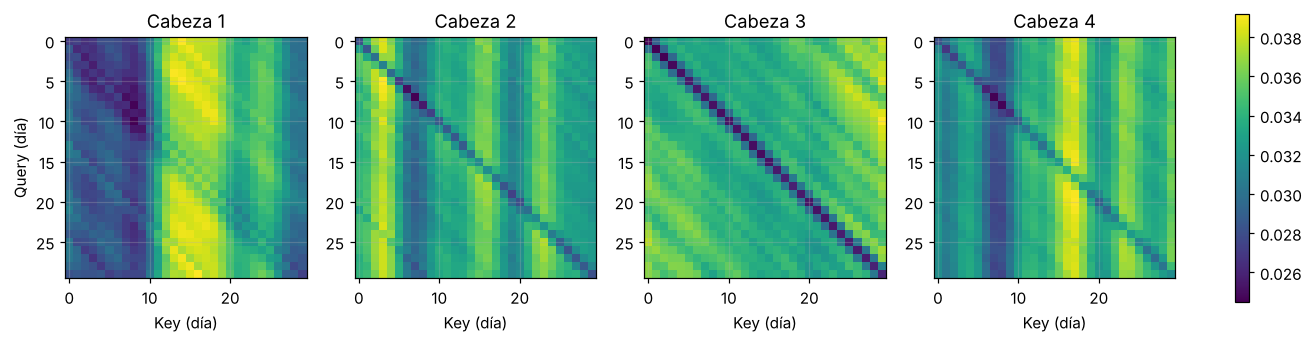

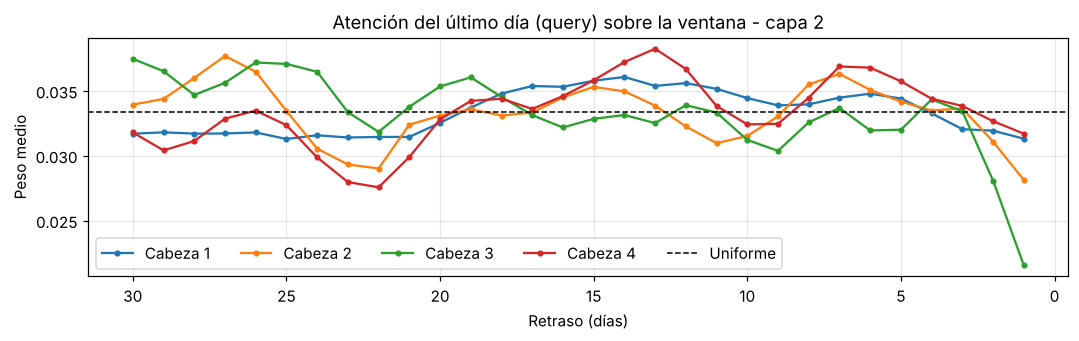

Cabeza 1: retrasos más atendidos [14, 15, 12] | peso en la última semana = 0.23
Cabeza 2: retrasos más atendidos [27, 26, 7] | peso en la última semana = 0.23
Cabeza 3: retrasos más atendidos [30, 26, 25] | peso en la última semana = 0.21
Cabeza 4: retrasos más atendidos [13, 14, 7] | peso en la última semana = 0.24


In [15]:
A = pesos_tr[-1].cpu().numpy()          # última capa: [N, h, T, T]
A_media = A.mean(0)                       # [h, T, T]
fig, ax = plt.subplots(1, 4, figsize=(14, 3.4))
for c in range(4):
    im = ax[c].imshow(A_media[c], cmap="viridis")
    ax[c].set_title(f"Cabeza {c + 1}"); ax[c].set_xlabel("Key (día)");
ax[0].set_ylabel("Query (día)")
plt.colorbar(im, ax=ax, fraction=.02); plt.savefig("figuras/atencion_cabezas.png", dpi=150, bbox_inches="tight"); plt.show()

retrasos = np.arange(LOOKBACK, 0, -1)
fila_ultimo = A_media[:, -1, :]           # [h, T]: a qué mira el último día
fig, ax = plt.subplots(figsize=(10, 3.2))
for c in range(4):
    ax.plot(retrasos, fila_ultimo[c], marker="o", ms=3, label=f"Cabeza {c + 1}")
ax.axhline(1 / LOOKBACK, color="k", ls="--", lw=1, label="Uniforme")
ax.invert_xaxis(); ax.set_xlabel("Retraso (días)"); ax.set_ylabel("Peso medio"); ax.legend(ncol=5)
ax.set_title("Atención del último día (query) sobre la ventana - capa 2")
plt.tight_layout(); plt.savefig("figuras/atencion_ultimo_dia.png", dpi=150); plt.show()

for c in range(4):
    top = np.argsort(-fila_ultimo[c])[:3]
    print(f"Cabeza {c + 1}: retrasos más atendidos {[int(retrasos[i]) for i in top]} | "
          f"peso en la última semana = {fila_ultimo[c][-7:].sum():.2f}")

## 8. Análisis y conclusiones

**Resultados en el año de prueba (1990)**

| Modelo | MAE (°C) | RMSE (°C) | R² | Épocas |
|---|---|---|---|---|
| Persistencia | 2,025 | 2,582 | 0,552 | - |
| LSTM | **1,722** | **2,244** | **0,661** | 60 |
| Transformer (último día) | 1,753 | 2,269 | 0,654 | 27 |
| Transformer último día, sin PE | 1,753 | 2,270 | 0,654 | 26 |
| Transformer (promedio) | 1,736 | 2,285 | 0,649 | 60 |
| Transformer promedio, sin PE | 1,981 | 2,616 | 0,540 | 38 |

1. **El Transformer construido a mano funciona.** Con 17 185 parámetros (casi los mismos que la LSTM) reduce el MAE de 2,03 °C (persistencia) a 1,75 °C, y su bloque de atención coincide con `nn.MultiheadAttention` hasta $10^{-8}$.
2. **Transformer y LSTM quedan prácticamente empatados** (diferencia de 0,03 °C). Con una sola variable, 2 890 ventanas de entrenamiento y horizonte de un día, el límite lo pone el ruido de la serie y no la arquitectura. Los Transformers muestran su ventaja con secuencias largas y muchos datos; aquí la LSTM, con su sesgo secuencial incorporado, ya es suficiente.
3. **Convergencia más rápida.** El Transformer alcanzó su mejor validación en la época ~17 y se detuvo en la 27; la LSTM siguió mejorando hasta la 60. Además, la atención procesa los 30 días en paralelo, mientras que la LSTM los recorre uno por uno (en GPU y con secuencias largas esta diferencia es decisiva).
4. **La codificación posicional sí importa, pero depende de cómo se lea la salida.** Si la predicción se toma del último token, quitar la PE no cambia nada, porque ese token ya contiene el valor de *ayer*. Cuando la salida es el promedio de los 30 días, quitar la PE hunde el R² de 0,649 a 0,540, **peor que la persistencia**: sin posición el modelo ve un conjunto de temperaturas y no sabe cuál es la más reciente. Es el mismo fenómeno de la práctica de clase con "el perro persigue al gato".
5. **Atención difusa.** Los pesos de las cuatro cabezas están cerca del uniforme (0,026-0,038). Cada cabeza tiene un patrón propio (la 1 y la 4 se fijan en la mitad de la ventana, la 3 evita la diagonal), pero en conjunto el modelo calcula algo parecido a un promedio ponderado del mes, coherente con una serie dominada por el nivel estacional.
6. **Validación menor que entrenamiento.** La pérdida de validación es más baja que la de entrenamiento porque el año 1989 fue menos variable y porque la pérdida de entrenamiento se calcula con dropout activo. No indica fuga de información: la partición es cronológica y la normalización usa solo datos de entrenamiento.

**Conclusión.** Se implementaron todos los componentes del encoder Transformer de Vaswani et al. (2017): embedding, codificación posicional sinusoidal, atención multi-cabeza, *feed-forward*, conexiones residuales y normalización de capa. El modelo igualó a la LSTM con menos épocas, y los experimentos de ablación mostraron con datos por qué la codificación posicional es indispensable cuando la atención debe razonar sobre el orden.

*Nota: en Colab los números pueden variar ligeramente por diferencias de hardware y versión de librerías.*